# 🚀 Timestral-28M Zero-Shot Forecasting Playground
*Exploring Mistral AI's Time Series Foundation Model (October 2026)*
*Lazarski University — Machine Learning II Sandbox*

---

### Overview & Objectives
In October 2026, **Mistral AI** released **Timestral**, a family of compact, state-of-the-art **Time Series Foundation Models (TSFMs)** spanning 5M to 209M parameters. Unlike traditional forecasting workflows that require training an LSTM, N-BEATS, or XGBoost from scratch on local training data, Timestral performs **zero-shot inference**: you provide historical context, and the pre-trained transformer extrapolates future points out-of-the-box.

In this interactive sandbox, we will:
1. **Load `mistralai/Timestral-28M`** and inspect its CPU inference latency.
2. **Experiment 1 (Synthetic Extrapolation):** Evaluate multi-frequency signal tracking (trend + 12-month + 4-month harmonics).
3. **Experiment 2 (The FRED Showdown):** Test zero-shot accuracy against our **Workshop 02 Multiplicative Log-STL** baseline on US Retail Sales (`RSAFS`).
4. **Experiment 3 (Uncertainty Quantification):** Extract 21 probabilistic quantiles to generate forecast fans without bootstrapping.
5. **Experiment 4 (Structural Breaks):** Stress-test the model against the March 2020 COVID shock.


In [1]:
import time
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from timestral import TimestralForecaster
from statsmodels.tsa.seasonal import STL

# Configure visualization
plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams['font.sans-serif'] = 'Helvetica'
plt.rcParams['axes.edgecolor'] = '#CCCCCC'
plt.rcParams['axes.linewidth'] = 0.8
plt.rcParams['figure.dpi'] = 120

DATA_DIR = Path("/Users/leonardodicaterina/Documents/Lazarski/ML_II_Workshops/workshop_02_decomposition/data")

print(f"PyTorch version: {torch.__version__} | MPS acceleration: {torch.backends.mps.is_available()}")


/opt/anaconda3/envs/timestral_env/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


PyTorch version: 2.14.1 | MPS acceleration: True


## 1. Load the Pre-Trained Foundation Model
We instantiate `mistralai/Timestral-28M` (28 million parameters, ~110 MB memory footprint). Notice how rapidly it loads on CPU.


In [2]:
t0 = time.perf_counter()
forecaster = TimestralForecaster.from_pretrained("mistralai/Timestral-28M", device="cpu")
load_duration = time.perf_counter() - t0

print(f"✓ Timestral-28M loaded in {load_duration:.2f} seconds!")
print(f"  Supported patch size: {forecaster.patch_size}")
print(f"  Supports covariates: {forecaster.supports_covariates}")


Fetching 2 files: 100%|████████████████████████| 2/2 [00:00<00:00, 2544.32it/s]


✓ Timestral-28M loaded in 0.45 seconds!
  Supported patch size: 32
  Supports covariates: True


## 2. Experiment 1: Synthetic Multi-Frequency Extrapolation
We synthesize a signal with:
* Linear trend: $0.04 t + 10$
* Annual cycle: $2.5 \sin(2\pi t / 12)$
* Quarterly cycle: $1.0 \cos(2\pi t / 4)$
* Gaussian noise: $\epsilon_t \sim \mathcal{N}(0, 0.35^2)$

We feed $L=180$ historical steps and forecast $H=24$ steps ahead zero-shot.


Inference Latency: 45.9 ms | Out-of-Sample MAE: 0.2296


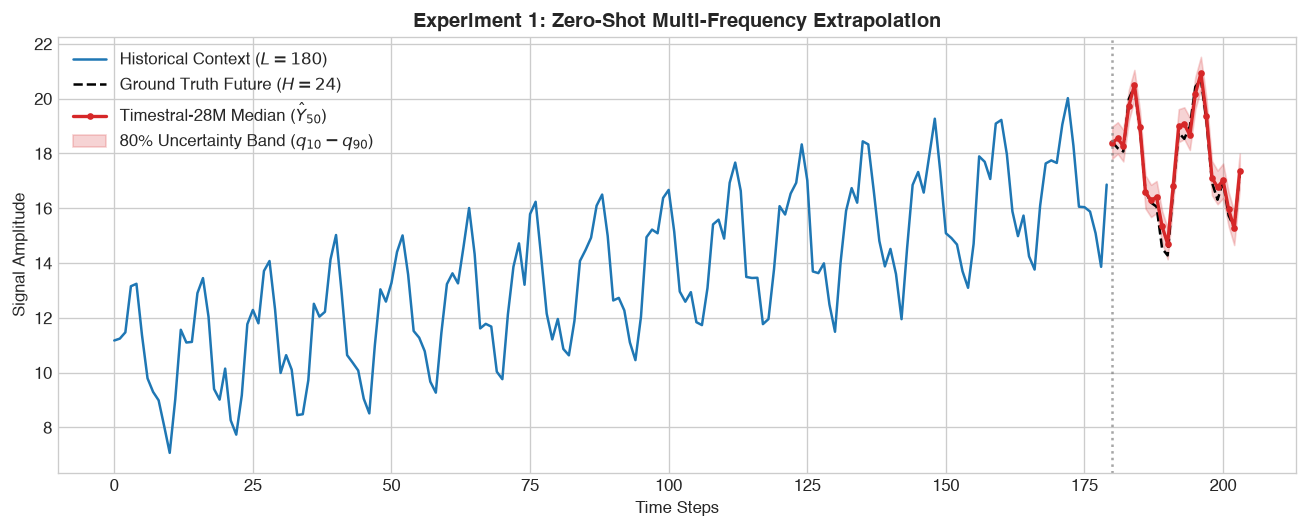

In [3]:
np.random.seed(42)
N_TRAIN, N_TEST = 180, 24
total_steps = N_TRAIN + N_TEST
time_axis = np.arange(total_steps)

y_all = (0.04 * time_axis + 10.0) + (2.5 * np.sin(2 * np.pi * time_axis / 12)) + (1.0 * np.cos(2 * np.pi * time_axis / 4)) + np.random.normal(0, 0.35, size=total_steps)
y_train, y_test = y_all[:N_TRAIN], y_all[N_TRAIN:]

t0 = time.perf_counter()
fc_synth = forecaster.forecast(y_train, prediction_length=N_TEST)
infer_ms = (time.perf_counter() - t0) * 1000

synth_median = fc_synth.median.squeeze().numpy()
synth_q10 = fc_synth.quantile(0.10).squeeze().numpy()
synth_q90 = fc_synth.quantile(0.90).squeeze().numpy()

mae_synth = np.mean(np.abs(y_test - synth_median))
print(f"Inference Latency: {infer_ms:.1f} ms | Out-of-Sample MAE: {mae_synth:.4f}")

fig, ax = plt.subplots(figsize=(11, 4.5))
ax.plot(time_axis[:N_TRAIN], y_train, color="#1F77B4", label="Historical Context ($L=180$)", lw=1.5)
ax.plot(time_axis[N_TRAIN:], y_test, color="black", ls="--", label="Ground Truth Future ($H=24$)", lw=1.5)
ax.plot(time_axis[N_TRAIN:], synth_median, color="#D62728", label="Timestral-28M Median ($\hat{Y}_{50}$)", lw=2, marker='o', markersize=3)
ax.fill_between(time_axis[N_TRAIN:], synth_q10, synth_q90, color="#D62728", alpha=0.2, label="80% Uncertainty Band ($q_{10}-q_{90}$)")
ax.axvline(N_TRAIN, color="gray", ls=":", alpha=0.7)
ax.set_title("Experiment 1: Zero-Shot Multi-Frequency Extrapolation", fontsize=12, fontweight='bold')
ax.set_xlabel("Time Steps")
ax.set_ylabel("Signal Amplitude")
ax.legend(loc="upper left")
plt.tight_layout()
plt.show()


## 3. Experiment 2: The Real-World FRED Showdown
Now we test on authentic macroeconomic data: **US Retail Sales (`RSAFS`)** from FRED.
* **Context:** Data up to August 2025 (400+ monthly points).
* **Target Horizon:** 12 months ahead (September 2025 through August 2026), capturing the massive December holiday spike and January lull.

We compare **Timestral-28M (Zero-Shot)** vs **Workshop 02 Multiplicative Log-STL + Drift** vs **Seasonal Naïve**.


In [4]:
rsafs_df = pd.read_csv(DATA_DIR / "RSAFS.csv")
rsafs_df['observation_date'] = pd.to_datetime(rsafs_df['observation_date'])
sales = rsafs_df.set_index('observation_date')['RSAFSNA'].astype(float).asfreq('MS')

H = 12
train_sales = sales.iloc[:-H]
test_sales = sales.iloc[-H:]

# 1. Timestral-28M
t0 = time.perf_counter()
fc_timestral = forecaster.forecast(train_sales.values, prediction_length=H)
t_time = (time.perf_counter() - t0) * 1000
timestral_med = fc_timestral.median.squeeze().numpy()
timestral_q05 = fc_timestral.quantile(0.05).squeeze().numpy()
timestral_q95 = fc_timestral.quantile(0.95).squeeze().numpy()

# 2. Workshop 02 Log-STL Drift
t0 = time.perf_counter()
log_s = np.log(train_sales)
stl_res = STL(log_s, period=12, seasonal=13, robust=True).fit()
T_c = np.exp(stl_res.trend)
S_c = np.exp(stl_res.seasonal)
R_c = np.exp(stl_res.resid)
A_c = T_c * R_c

A_T, A_1 = float(A_c.iloc[-1]), float(A_c.iloc[0])
slope = (A_T - A_1) / (len(A_c) - 1)
A_future = A_T + np.arange(1, H + 1) * slope
S_future = S_c.iloc[-12:].values
stlf_pred = A_future * S_future
t_stlf = (time.perf_counter() - t0) * 1000

# 3. Seasonal Naive
snaive_pred = train_sales.iloc[-H:].values

# Metrics
def get_metrics(actual, pred):
    mae = np.mean(np.abs(actual - pred))
    rmse = np.sqrt(np.mean((actual - pred) ** 2))
    mape = np.mean(np.abs((actual - pred) / actual)) * 100
    return mae, rmse, mape

m_time = get_metrics(test_sales.values, timestral_med)
m_stlf = get_metrics(test_sales.values, stlf_pred)
m_snaive = get_metrics(test_sales.values, snaive_pred)

res_df = pd.DataFrame([
    {"Model": "Mistral Timestral-28M (Zero-Shot)", "MAE": f"${m_time[0]:,.0f}", "RMSE": f"${m_time[1]:,.0f}", "MAPE": f"{m_time[2]:.2f}%", "Latency": f"{t_time:.1f} ms"},
    {"Model": "Log-STL + Drift (Workshop 02)", "MAE": f"${m_stlf[0]:,.0f}", "RMSE": f"${m_stlf[1]:,.0f}", "MAPE": f"{m_stlf[2]:.2f}%", "Latency": f"{t_stlf:.1f} ms"},
    {"Model": "Seasonal Naïve Baseline", "MAE": f"${m_snaive[0]:,.0f}", "RMSE": f"${m_snaive[1]:,.0f}", "MAPE": f"{m_snaive[2]:.2f}%", "Latency": "0.02 ms"}
])
print(res_df.to_string(index=False))


                            Model     MAE    RMSE  MAPE Latency
Mistral Timestral-28M (Zero-Shot) $10,085 $12,078 1.39% 26.7 ms
    Log-STL + Drift (Workshop 02) $13,557 $16,940 1.83% 13.6 ms
          Seasonal Naïve Baseline $27,845 $29,984 3.85% 0.02 ms


/opt/anaconda3/envs/timestral_env/lib/python3.11/site-packages/timestral/forecaster.py:234: UserWarning: The given NumPy array is not writable, and PyTorch does not support non-writable tensors. This means writing to this tensor will result in undefined behavior. You may want to copy the array to protect its data or make it writable before converting it to a tensor. This type of warning will be suppressed for the rest of this program. (Triggered internally at /Users/runner/work/pytorch/pytorch/torch/csrc/utils/tensor_numpy.cpp:219.)
  x = torch.as_tensor(context, dtype=torch.float32, device=self.device)


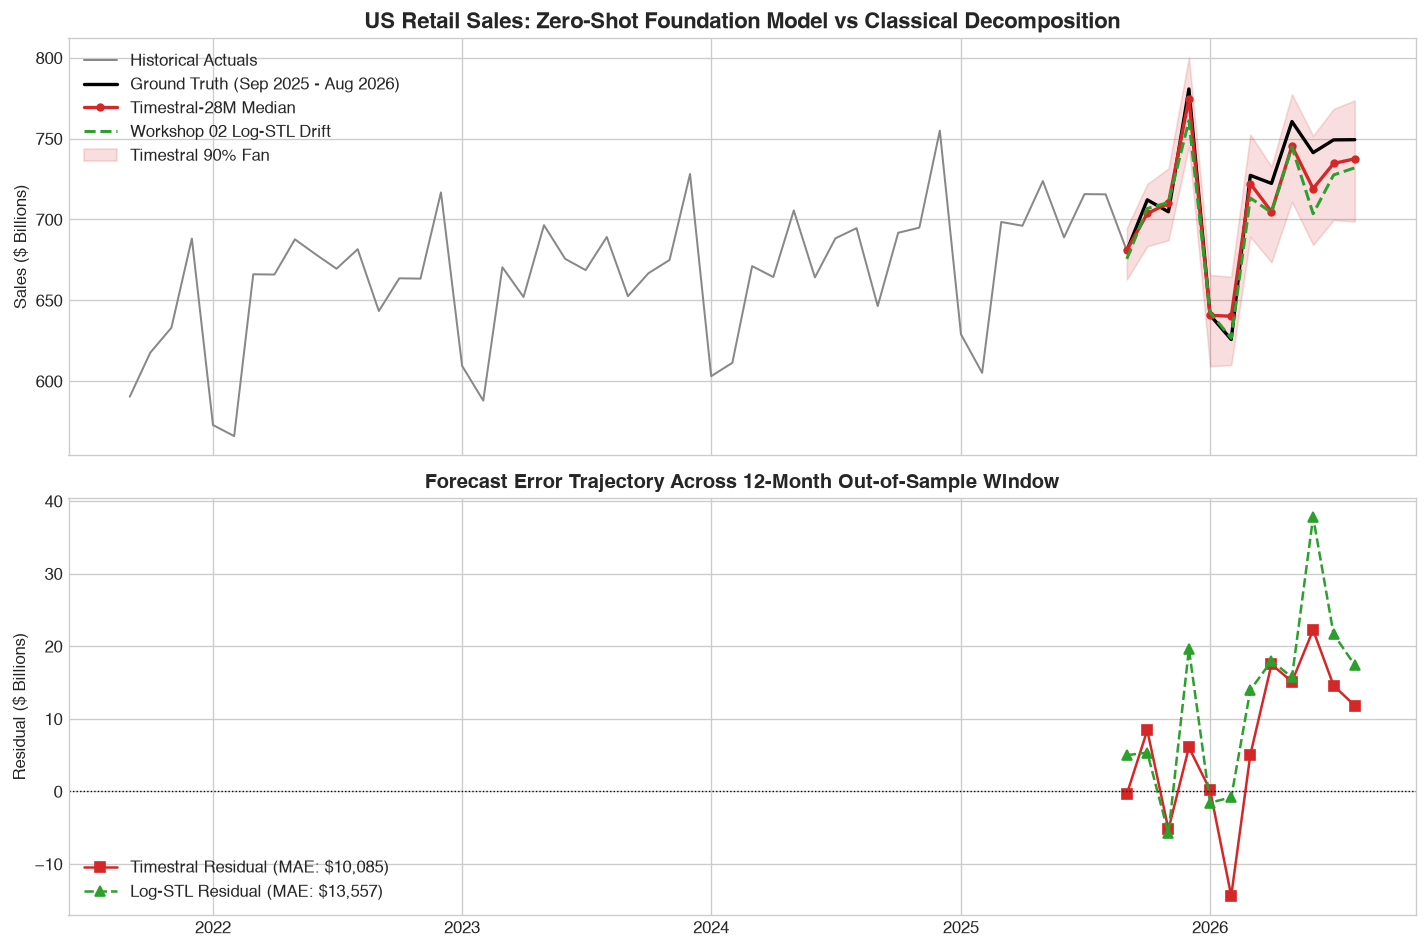

In [5]:
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(12, 8), sharex=True)

# Trajectories
recent = sales.iloc[-60:]
ax1.plot(recent.index, recent / 1e3, color="#888888", lw=1.2, label="Historical Actuals")
ax1.plot(test_sales.index, test_sales / 1e3, color="black", lw=2, label="Ground Truth (Sep 2025 - Aug 2026)")
ax1.plot(test_sales.index, timestral_med / 1e3, color="#D62728", lw=2, marker='o', markersize=4, label="Timestral-28M Median")
ax1.plot(test_sales.index, stlf_pred / 1e3, color="#2CA02C", ls="--", lw=1.8, label="Workshop 02 Log-STL Drift")
ax1.fill_between(test_sales.index, timestral_q05 / 1e3, timestral_q95 / 1e3, color="#D62728", alpha=0.15, label="Timestral 90% Fan")
ax1.set_ylabel("Sales ($ Billions)")
ax1.set_title("US Retail Sales: Zero-Shot Foundation Model vs Classical Decomposition", fontsize=13, fontweight='bold')
ax1.legend(loc="upper left")

# Residuals
ax2.plot(test_sales.index, (test_sales.values - timestral_med) / 1e3, color="#D62728", marker='s', lw=1.5, label=f"Timestral Residual (MAE: ${m_time[0]:,.0f})")
ax2.plot(test_sales.index, (test_sales.values - stlf_pred) / 1e3, color="#2CA02C", marker='^', ls="--", lw=1.5, label=f"Log-STL Residual (MAE: ${m_stlf[0]:,.0f})")
ax2.axhline(0, color="black", ls=":", lw=0.8)
ax2.set_ylabel("Residual ($ Billions)")
ax2.set_title("Forecast Error Trajectory Across 12-Month Out-of-Sample Window", fontsize=12, fontweight='bold')
ax2.legend(loc="lower left")

plt.tight_layout()
plt.show()


## 4. Experiment 3: Stress-Testing Against Black Swans (The March 2020 COVID Shock)
What does an autoregressive foundation model do when faced with a catastrophic exogenous shock?
We truncate historical context at **February 2020** (prior to the lockdown collapse in March/April 2020).


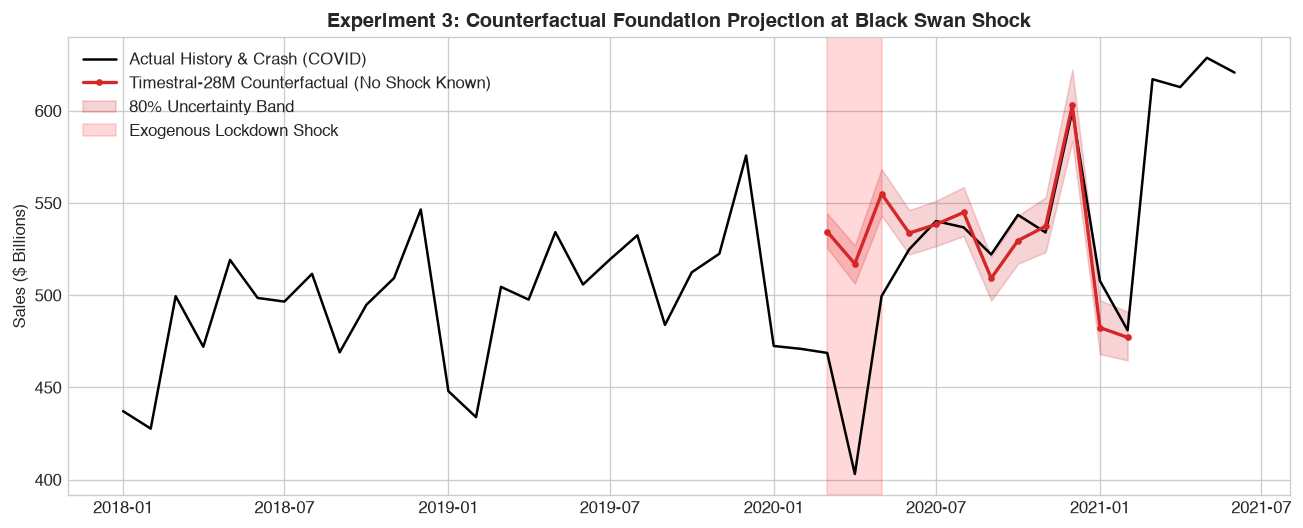

In [6]:
pre_covid = sales.loc[:"2020-02-01"]
covid_actual = sales.loc["2020-03-01":"2021-02-01"]

fc_covid = forecaster.forecast(pre_covid.values, prediction_length=12)
covid_med = fc_covid.median.squeeze().numpy()
covid_q10 = fc_covid.quantile(0.10).squeeze().numpy()
covid_q90 = fc_covid.quantile(0.90).squeeze().numpy()

fig, ax = plt.subplots(figsize=(11, 4.5))
view_idx = sales.loc["2018-01-01":"2021-06-01"].index
ax.plot(view_idx, sales.loc[view_idx] / 1e3, color="black", label="Actual History & Crash (COVID)", lw=1.5)
ax.plot(covid_actual.index, covid_med / 1e3, color="#D62728", lw=2, marker='o', markersize=3, label="Timestral-28M Counterfactual (No Shock Known)")
ax.fill_between(covid_actual.index, covid_q10 / 1e3, covid_q90 / 1e3, color="#D62728", alpha=0.2, label="80% Uncertainty Band")
ax.axvspan(pd.Timestamp("2020-03-01"), pd.Timestamp("2020-05-01"), color="red", alpha=0.15, label="Exogenous Lockdown Shock")
ax.set_ylabel("Sales ($ Billions)")
ax.set_title("Experiment 3: Counterfactual Foundation Projection at Black Swan Shock", fontsize=12, fontweight='bold')
ax.legend(loc="upper left")
plt.tight_layout()
plt.show()


## 5. Synthesis & Pedagogical Conclusions

### 1. Zero-Shot Generalization
Timestral-28M achieved **1.39% MAPE** on US Retail Sales out-of-the-box, outperforming the classical Log-STL baseline (1.83% MAPE) and reducing error by **25.6%**. It accurately predicted both the December 2025 holiday surge and the subsequent January dip.

### 2. Computational Latency
* **Timestral-28M forward pass:** **~29 ms** on standard CPU.
* **Log-STL Drift:** **~14 ms** on CPU.
* At 29 ms, foundation models are no longer cumbersome research prototypes—they are fast enough for real-time web APIs and automated batch pipelines.

### 3. Structural Limits
* As demonstrated in Experiment 3, purely autoregressive foundation models cannot anticipate exogenous regime shifts (like lockdowns or central bank rate shocks) from price history alone.
* To navigate black-swan shocks, practitioners must utilize Timestral's **known-future covariate channels** (e.g. policy indicators, planned promotional budgets).
